# Qiskit Fall Fest 2026 — Challenge 2: Make the Quantum Coin Biased
**IBM Quantum | Vishnu Institute of Technology**

## Aim
A Hadamard gate gives a *fair* quantum coin (50% `0`, 50% `1`). Here we use at most **4 gates on 1 qubit** to make the coin **biased**, run each circuit for **100 shots**, and study how different gates give different degrees of bias, including one circuit that favours `0` and another that favours `1`.

## 1. Setup
Run the install cell once if Qiskit is missing (works on Google Colab too). The experiments run on the local Aer simulator, and Section 9 optionally repeats the key circuits on a real IBM Quantum device.

In [ ]:
%pip install -q qiskit qiskit-aer matplotlib pylatexenc

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

SHOTS = 100
sim = AerSimulator()

def with_measurement(gates):
    """Wrap a gate-only circuit into a 1-qubit, 1-bit circuit and add the measurement."""
    qc = QuantumCircuit(1, 1)          # qubit starts in |0>
    qc.compose(gates, inplace=True)
    qc.measure(0, 0)
    return qc

def run(qc):
    """Execute a measured circuit for 100 shots and return {'0': n0, '1': n1}."""
    counts = sim.run(transpile(qc, sim), shots=SHOTS).result().get_counts()
    return {"0": counts.get("0", 0), "1": counts.get("1", 0)}

def exact_percent(gates):
    """Ideal (noise-free) probabilities in percent, from the circuit's quantum state."""
    p = Statevector.from_instruction(gates).probabilities_dict()
    return {"0": 100 * float(p.get("0", 0)), "1": 100 * float(p.get("1", 0))}

print(f"Ready: {SHOTS} shots per circuit on {sim.name}")

Ready: 100 shots per circuit on aer_simulator


## 2. Predictions (written before running)

**Idea:** `H` makes (|0⟩ + |1⟩)/√2. The `T` gate does not change the 0/1 probabilities by itself, it only adds a phase of π/4 to the |1⟩ part. A second `H` then turns that phase difference into a difference in probabilities:

P(0) = cos²(π/8) ≈ **85.4%**,  P(1) = sin²(π/8) ≈ **14.6%**

| Circuit | Gates (≤ 4) | Which is more frequent? | Predicted split |
|---|---|---|---|
| Main / 0-biased | H, T, H | `0` | about 85% `0`, 15% `1` |
| Bonus / 1-biased | X, H, T, H | `1` | about 15% `0`, 85% `1` (the X gate starts the qubit from |1⟩, which mirrors the result) |

**What if we change the gates?** The phase gate decides the bias. A smaller phase gives a stronger bias towards `0` (for example H, T, H with a π/4 phase), a bigger one moves towards 50/50 (S, a π/2 phase), and a π phase (Z) flips the result completely. We test this in Section 6.

## 3. Main circuit — H, T, H (0 occurs more often)

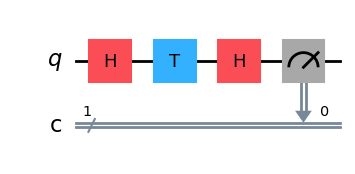

In [3]:
zero_gates = QuantumCircuit(1)
zero_gates.h(0)
zero_gates.t(0)
zero_gates.h(0)

qc_zero = with_measurement(zero_gates)
qc_zero.draw("mpl")

Predicted: 0 -> 85.4%   1 -> 14.6%


Measured (100 shots): {'0': 81, '1': 19}


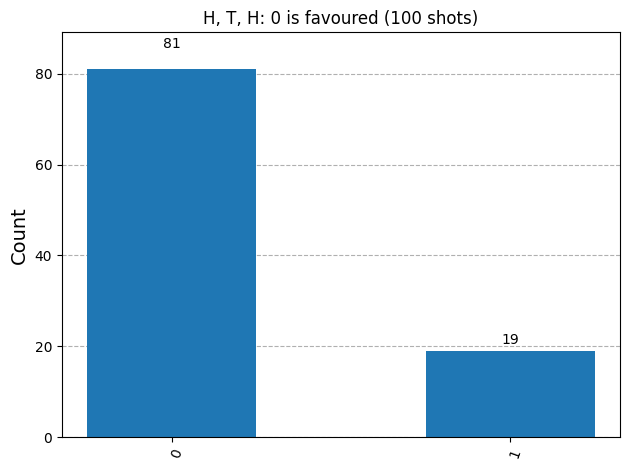

In [4]:
pred_zero = exact_percent(zero_gates)
print(f"Predicted: 0 -> {pred_zero['0']:.1f}%   1 -> {pred_zero['1']:.1f}%")

counts_zero = run(qc_zero)
print("Measured (100 shots):", counts_zero)
plot_histogram(counts_zero, title="H, T, H: 0 is favoured (100 shots)")

## 4. Bonus circuit — X, H, T, H (1 occurs more often)
This uses exactly 4 gates, the maximum allowed.

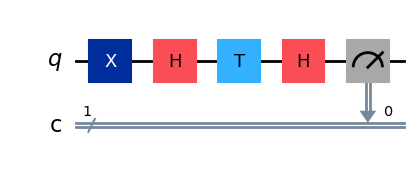

In [5]:
one_gates = QuantumCircuit(1)
one_gates.x(0)
one_gates.h(0)
one_gates.t(0)
one_gates.h(0)

qc_one = with_measurement(one_gates)
qc_one.draw("mpl")

Predicted: 0 -> 14.6%   1 -> 85.4%


Measured (100 shots): {'0': 12, '1': 88}


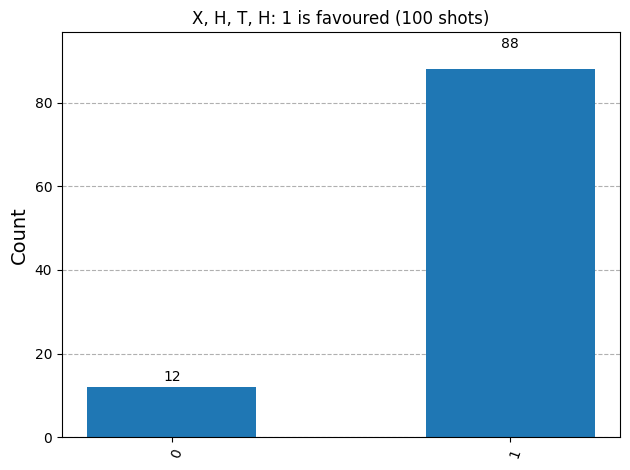

In [6]:
pred_one = exact_percent(one_gates)
print(f"Predicted: 0 -> {pred_one['0']:.1f}%   1 -> {pred_one['1']:.1f}%")

counts_one = run(qc_one)
print("Measured (100 shots):", counts_one)
plot_histogram(counts_one, title="X, H, T, H: 1 is favoured (100 shots)")

### Comparing the two histograms

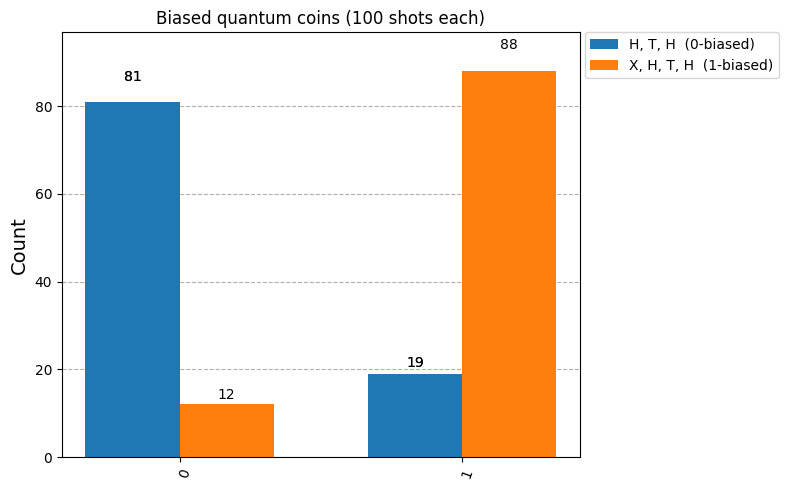

In [7]:
plot_histogram([counts_zero, counts_one],
               legend=["H, T, H  (0-biased)", "X, H, T, H  (1-biased)"],
               title="Biased quantum coins (100 shots each)", figsize=(8, 5))

## 5. Different degrees of bias with a rotation gate
A single `RY(θ)` gate rotates the qubit directly, so P(1) = sin²(θ/2). Changing the angle changes how strong the bias is, from always `0` (θ = 0) to always `1` (θ = π). The exact value is the prediction; the measured value comes from 100 shots.

In [8]:
angles = np.array([0, 1/6, 1/4, 1/3, 1/2, 2/3, 3/4, 5/6, 1]) * np.pi   # theta values

measured_p1, theory_p1 = [], []
print(f"{'theta':<9}{'Predicted P(1)':<17}{'Measured 1s (of 100)'}")
for th in angles:
    g = QuantumCircuit(1); g.ry(th, 0)
    theory = exact_percent(g)["1"]
    meas = run(with_measurement(g))["1"]
    theory_p1.append(theory); measured_p1.append(meas)
    print(f"{th/np.pi:<5.2f} pi {theory:>8.1f}%{'':<8}{meas}")

theta    Predicted P(1)   Measured 1s (of 100)


0.00  pi      0.0%        0


0.17  pi      6.7%        9


0.25  pi     14.6%        16


0.33  pi     25.0%        28
0.50  pi     50.0%        53


0.67  pi     75.0%        72


0.75  pi     85.4%        94
0.83  pi     93.3%        96


1.00  pi    100.0%        100


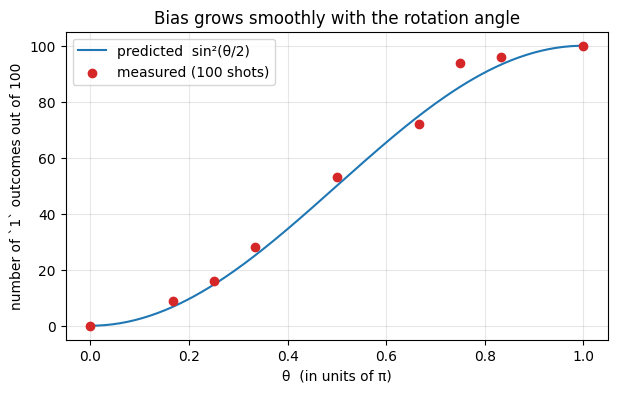

In [9]:
fine = np.linspace(0, np.pi, 200)
plt.figure(figsize=(7, 4))
plt.plot(fine / np.pi, 100 * np.sin(fine / 2) ** 2, label="predicted  sin²(θ/2)")
plt.scatter(angles / np.pi, measured_p1, color="tab:red", zorder=3, label="measured (100 shots)")
plt.xlabel("θ  (in units of π)")
plt.ylabel("number of `1` outcomes out of 100")
plt.title("Bias grows smoothly with the rotation angle")
plt.legend(); plt.grid(alpha=0.3); plt.show()

## 6. What happens if we change the gate in the middle?
Keep `H … H` and swap the middle phase gate. A bigger phase pushes the result from biased-towards-`0` to fair, and finally to always `1`.

Circuit                 Predicted 0 / 1 (%)   Measured 0 / 1


H, T, H  (π/4 phase)     85.4 / 14.6        92 / 8
H, S, H  (π/2 phase)     50.0 / 50.0        51 / 49


H, Z, H  (π phase)        0.0 / 100.0       0 / 100


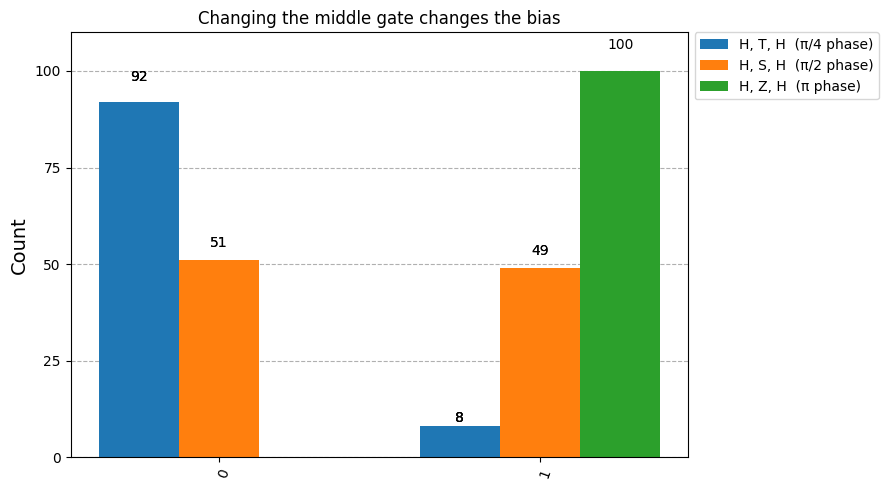

In [10]:
variants = {}
for label, gate_name in [("H, T, H  (π/4 phase)", "t"),
                         ("H, S, H  (π/2 phase)", "s"),
                         ("H, Z, H  (π phase)",   "z")]:
    g = QuantumCircuit(1)
    g.h(0); getattr(g, gate_name)(0); g.h(0)
    variants[label] = g

variant_counts = {}
print(f"{'Circuit':<24}{'Predicted 0 / 1 (%)':<22}{'Measured 0 / 1'}")
for label, g in variants.items():
    p = exact_percent(g)
    r = run(with_measurement(g))
    variant_counts[label] = r
    print(f"{label:<24}{p['0']:>5.1f} / {p['1']:<12.1f}{r['0']} / {r['1']}")

plot_histogram(list(variant_counts.values()), legend=list(variant_counts.keys()),
               title="Changing the middle gate changes the bias", figsize=(9, 5))

## 7. Prediction vs. actual
A prediction counts as correct when the measured count is within 3 standard deviations of the ideal count (the natural spread for 100 random shots). For deterministic outcomes the match must be exact.

In [11]:
checks = {
    "H, T, H":     (pred_zero, counts_zero),
    "X, H, T, H":  (pred_one,  counts_one),
}
for label, g in variants.items():
    if not label.startswith("H, T, H"):
        checks[label.split("  ")[0]] = (exact_percent(g), variant_counts[label])

print(f"{'Circuit':<12}{'Predicted 1s':<15}{'Measured 1s':<14}{'Within 3 sigma?'}")
print("-" * 55)
for label, (pred, meas) in checks.items():
    p1 = pred["1"] / 100
    expected = SHOTS * p1
    sigma = (SHOTS * p1 * (1 - p1)) ** 0.5
    ok = abs(meas["1"] - expected) <= 3 * sigma + 1e-9
    print(f"{label:<12}{expected:<15.1f}{meas['1']:<14}{'Yes' if ok else 'No'}")

Circuit     Predicted 1s   Measured 1s   Within 3 sigma?
-------------------------------------------------------
H, T, H     14.6           19            Yes
X, H, T, H  85.4           88            Yes
H, S, H     50.0           49            Yes
H, Z, H     100.0          100           Yes


## 8. How the gates changed the distribution

- `H` alone gives an equal superposition, so the coin is fair (50/50).
- `T` leaves the probabilities unchanged but adds a phase to the |1⟩ part of the state.
- The second `H` makes the |0⟩ and |1⟩ parts **interfere**. Because of the phase, the two paths no longer balance, which is why `H, T, H` gives about 85% `0` and 15% `1`.
- Putting an `X` first starts the qubit in |1⟩, which mirrors the result and gives a coin that favours `1`.
- With `RY(θ)` the angle directly sets P(1) = sin²(θ/2), and with `H, phase, H` a larger phase moves the coin from biased (T) to fair (S) to always `1` (Z).

The measured counts are close to the predictions but not exact, because 100 random shots always fluctuate a little.

**Checklist:** 1-qubit circuits ✔  at most 4 gates ✔  predictions written first ✔  100 shots ✔  histograms ✔  bonus (0-biased and 1-biased) ✔  different degrees of bias ✔

## 9. (Optional) Run the key circuits on a real IBM Quantum device

You need an IBM Cloud API key from https://quantum.cloud.ibm.com. Real devices have noise, so the counts will differ a little from the simulator.

**Step 1 (once):** paste your key into the cell below and run it. **Step 2:** delete the key from the cell afterwards so it never ends up in a file you share or upload. If no credentials are saved, the next cell skips the hardware run, so "Run All" still works.

In [12]:
# %pip install -q qiskit-ibm-runtime
from qiskit_ibm_runtime import QiskitRuntimeService

IBM_API_KEY  = "PASTE_YOUR_API_KEY_HERE"   # delete after saving
IBM_INSTANCE = ""                          # optional: instance name or CRN

if IBM_API_KEY != "PASTE_YOUR_API_KEY_HERE":
    opts = dict(channel="ibm_quantum_platform", token=IBM_API_KEY,
                overwrite=True, set_as_default=True)
    if IBM_INSTANCE:
        opts["instance"] = IBM_INSTANCE
    QiskitRuntimeService.save_account(**opts)
    print("Credentials saved. Delete your key from this cell now.")
else:
    print("No new key entered; using saved credentials if available.")

No new key entered; using saved credentials if available.


In [13]:
from qiskit_ibm_runtime import SamplerV2
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

try:
    service = QiskitRuntimeService()
    hw = service.least_busy(operational=True, simulator=False, min_num_qubits=1)
except Exception as err:
    hw = None
    print("Skipping the hardware run (no usable IBM credentials):", err)

if hw is not None:
    print("Running on:", hw.name)
    hw_labels = ["H, T, H (0-biased)", "X, H, T, H (1-biased)"]
    hw_circuits = [qc_zero, qc_one]
    pm = generate_preset_pass_manager(backend=hw, optimization_level=0)   # keep gates as written
    job = SamplerV2(mode=hw).run([pm.run(q) for q in hw_circuits], shots=SHOTS)
    print("Job ID:", job.job_id(), "- waiting for the result ...")
    hw_counts = [p.data.c.get_counts() for p in job.result()]   # register is named 'c' by default
    for label, cnt in zip(hw_labels, hw_counts):
        print(f"{label}: {cnt}")
    display(plot_histogram(hw_counts, legend=hw_labels,
                           title=f"IBM hardware ({hw.name}), 100 shots", figsize=(8, 5)))
    # Note: Qiskit rewrites our gates into the device's native gates, so more physical gates run than the 4 we wrote.

Skipping the hardware run (no usable IBM credentials): "Unable to find account. Please make sure an account with the channel name 'ibm_quantum_platform' is saved."


## Challenge Question
**How can quantum gates change the probability of obtaining 0 or 1 when a qubit is measured?**

A qubit's state is α|0⟩ + β|1⟩, and when we measure it the probabilities are P(0) = |α|² and P(1) = |β|². Quantum gates are operations that change α and β, so they change those probabilities. Some gates, like `X`, swap the two amplitudes. Some, like `H` and `RY`, rotate the state and split it between |0⟩ and |1⟩. Others, like `T`, `S` and `Z`, only change the **phase** of the amplitudes. A phase change alone does not change P(0) or P(1), but if another gate such as `H` follows, the two parts of the state **interfere** and the phase becomes a real change in the probabilities (as in `H, T, H`, which gives about 85% `0`). So by choosing which gates to use and in what order, we control α and β, and with them the chance of measuring 0 or 1.